<a href="https://colab.research.google.com/github/OmaRecalde/machinelearning2026/blob/main/Ejercicio_imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SISTEMA INTELIGENTE PARA LA CLASIFICACIÓN DE RESIDUOS RECICLABLES MEDIANTE VISIÓN ARTIFICIAL BAJO LA METODOLOGÍA CRISP-DM

Nombre Estudiante: OMAR RECALDE

LINK GITHUB:

# FASE 1 - COMPRENSIÓN DEL NEGOCIO (CRISP-DM)

## Problema

La clasificación manual presenta errores humanos.

## Pregunta de investigación

¿Es posible desarrollar un sistema inteligente basado en EfficientNetB0?

# FASE 2 - COMPRENSIÓN DE LOS DATOS (CRISP-DM)

# ============================================================
# INSTALACION DE LIBRERIAS
# ============================================================
#   - tensorflow      -> crear y entrenar la red neuronal (Deep Learning)
#   - matplotlib      -> dibujar graficas (accuracy, loss, distribucion)
#   - seaborn         -> permite mejor diseño de graficas (matriz de confusion)
#   - scikit-learn    -> metricas de evaluacion (reporte y matriz de confusion)
!pip install tensorflow matplotlib seaborn scikit-learn -q

In [2]:
# IMPORTACION DE LIBRERIAS

import os                         # manejar carpetas y rutas de archivos
import numpy as np                # operaciones con matrices/numeros (arrays)
import pandas as pd               # manejar tablas de datos
import matplotlib.pyplot as plt   # graficas basicas
import seaborn as sns             # graficas estadisticas (matriz de confusion)
import tensorflow as tf           # libreria principal de Deep Learning

# Descargar Dataset

Se utiliza el dataset **TrashNet** (Gary Thung y Mindy Yang, Stanford), descargado desde su repositorio oficial de GitHub. Contiene 2527 imágenes de residuos clasificadas en 6 categorías.

In [3]:
# DESCARGAR EL DATASET TRASHNET DESDE GITHUB
!git clone -q --depth 1 https://github.com/garythung/trashnet

# Descomprimir en la carpeta "dataset" (se excluyen archivos ocultos de Mac que no son imagenes)
!unzip -q -o trashnet/data/dataset-resized.zip -d dataset -x "__MACOSX/*" "*.DS_Store"

In [4]:
# Ruta (direccion de la carpeta) donde quedaron las imagenes ya descomprimidas.
ruta_datos = "dataset/dataset-resized"

In [5]:
# Listar las subcarpetas (clases) que hay dentro del dataset.
# sorted() = orden alfabetico, el mismo orden que usa Keras para las etiquetas
lista_datos = sorted(os.listdir(ruta_datos))
print(lista_datos)

['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [6]:
# CONTAR CUANTAS IMAGENES HAY POR CLASE

nombre_clases = []     # lista vacia para guardar los nombres de las clases
cantidad = []          # lista vacia para guardar cuantas imagenes tiene cada clase

# Recorremos una por una las carpetas que hay dentro de ruta_datos
for clase in lista_datos:
    ruta_clase = os.path.join(ruta_datos, clase)
    cant_img_clase = len(os.listdir(ruta_clase))
    nombre_clases.append(clase)
    cantidad.append(cant_img_clase)

total_imagenes = sum(cantidad)

print(f"{len(nombre_clases)} clases")
print(f"{total_imagenes} imagenes")

# Utilizar DataFrame de pandas para ver clase y cantidad ordenado
tabla = pd.DataFrame({
    "Clase": nombre_clases,
    "Cantidad": cantidad
})

tabla

6 clases
2527 imagenes


,Clase,Cantidad
0,cardboard,403
1,glass,501
2,metal,410
3,paper,594
4,plastic,482
5,trash,137


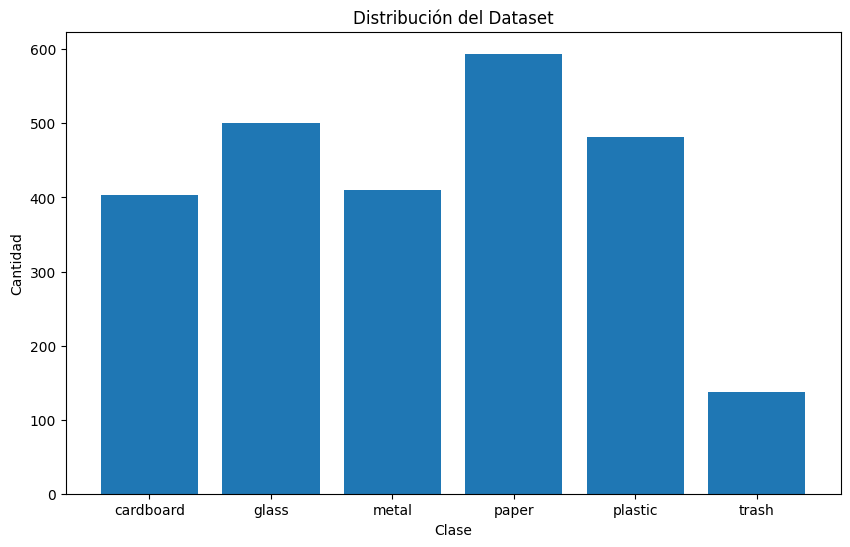

In [7]:
# GRAFICA DE BARRAS: DISTRIBUCION DEL DATASET

plt.figure(figsize=(10, 6))          # crea el lienzo de la grafica con tamano 10x6 pulgadas
plt.bar(nombre_clases, cantidad)     # dibuja barras: eje X = clases, altura = cantidad de imagenes
plt.title("Distribución del Dataset")  # titulo de la grafica
plt.xlabel("Clase")                  # etiqueta del eje X: nombre de la clase
plt.ylabel("Cantidad")               # etiqueta del eje Y: numero de imagenes
plt.show()                           # muestra la grafica en pantalla

# FASE 3 - PREPARACIÓN DE LOS DATOS

In [8]:
# PARAMETROS DE LAS IMAGENES

tamano_imagen = (224, 224)

tamano_lote = 32   # define el numero de imagenes que se procesan juntas en cada paso
                   # (un "lote"; ayuda a entrenar mas rapido y de forma estable)

In [9]:
# CARGAR IMAGENES DE ENTRENAMIENTO (70%)

# Lee las imagenes desde las carpetas y las convierte en un dataset de TensorFlow.
# Keras asigna automaticamente la etiqueta segun el nombre de la carpeta.

datos_entrenamiento = tf.keras.utils.image_dataset_from_directory(
    ruta_datos,              # carpeta que contiene las subcarpetas por clase
    validation_split=0.30,   # reserva un 30% para validacion/prueba
    subset="training",       # pedimos el 70% de ENTRENAMIENTO
    seed=123,                # semilla fija: hace que el reparto sea siempre el mismo
    image_size=tamano_imagen,   # redimensiona cada imagen a 224x224
    batch_size=tamano_lote      # agrupa las imagenes en lotes de 32
)

Found 2527 files belonging to 6 classes.
Using 1769 files for training.


In [10]:
# CARGAR EL 30% RESTANTE (se dividira luego en validacion + prueba)

# Usa la MISMA semilla (123) que el entrenamiento para no mezclar imagenes entre conjuntos.

datos_temporales = tf.keras.utils.image_dataset_from_directory(
    ruta_datos,              # misma carpeta de imagenes
    validation_split=0.30,   # mismo 30% reservado
    subset="validation",     # ahora pedimos ese 30% restante
    seed=123,                # MISMA semilla -> el reparto es consistente con el de entrenamiento
    image_size=tamano_imagen,   # mismo tamano 224x224
    batch_size=tamano_lote      # mismos lotes de 32
)

Found 2527 files belonging to 6 classes.
Using 758 files for validation.


In [11]:
# ============================================================
# DIVIDIR EL 30% EN: PRUEBA (15%) + VALIDACION (15%)
# ============================================================
# datos_temporales (30%) se parte en dos mitades iguales:
#   - datos_prueba      -> para la evaluacion FINAL (datos que el modelo nunca vio)
#   - datos_validacion  -> para vigilar el entrenamiento epoca a epoca

lotes_validacion = tf.data.experimental.cardinality(datos_temporales)  # cuenta cuantos lotes hay

datos_prueba = datos_temporales.take(lotes_validacion // 2)      # toma la PRIMERA mitad de los lotes -> prueba
datos_validacion = datos_temporales.skip(lotes_validacion // 2)  # salta esa mitad y toma el resto -> validacion

In [12]:
# ============================================================
# OPTIMIZACION DE DATOS
# ============================================================

# Normalización
# EfficientNetB0 YA normaliza las imagenes por dentro y espera los pixeles
# en el rango [0, 255]. Si se divide entre 255 el rango se convierte en [0, 1] y se rompe esa normalizacion interna.

# 1) Orden de las clases (alfabetico). Es el que usa el modelo internamente
#    y el que se debe usar en el reporte y en la matriz de confusion.
print("Orden REAL de las clases:", nombre_clases)

# 2) Optimizacion de rendimiento (cache + prefetch = entrena mas rapido).
#    NO cambia los datos, solo acelera la lectura desde el disco.
autotune = tf.data.AUTOTUNE

datos_entrenamiento = datos_entrenamiento.cache().prefetch(autotune)
datos_validacion    = datos_validacion.cache().prefetch(autotune)
datos_prueba        = datos_prueba.cache().prefetch(autotune)

Orden REAL de las clases: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


# FASE 4 - MODELADO

In [13]:
# ============================================================
# CARGAR EL MODELO BASE: EfficientNetB0 (TRANSFER LEARNING)
# ============================================================
# En vez de entrenar una red desde cero (necesitaria millones de imagenes),
# reutilizamos EfficientNetB0 que YA aprendio a "ver" con ImageNet.
from tensorflow.keras.applications import EfficientNetB0

modelo_base = EfficientNetB0(
    weights='imagenet',          # trae los pesos ya entrenados con millones de imagenes
    include_top=False,           # quitamos la ultima capa original (1000 clases de ImageNet)
                                 # para poner la nuestra (6 clases de residuos)
    input_shape=(224, 224, 3)    # tamano de entrada = 224x224 pixeles, 3 canales de color (RGB)
)

modelo_base.trainable = False    # CONGELAMOS el modelo base.
                                 # No se reentrena; solo aprovechamos lo que ya sabe

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
from tensorflow.keras.applications.efficientnet import preprocess_input

# CONSTRUIR EL MODELO

aumento_datos = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),                        # voltea la imagen al azar
    tf.keras.layers.RandomRotation(0.15),                            # la rota un poco (15%) al azar
    tf.keras.layers.RandomZoom(0.15),                                # le hace zoom (15%) al azar
    tf.keras.layers.RandomTranslation(0.1, 0.1),                     # la mueve (el objeto no siempre va centrado)
    tf.keras.layers.RandomContrast(0.2),                             # varia el contraste (ayuda con reflejos)
    tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),     # varia el brillo (luz de la camara)
], name="aumento_de_datos")

modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),     # capa de entrada, recibe imagenes 224x224 RGB
    aumento_datos,                                  # aplica las variaciones (solo durante el entrenamiento)
    tf.keras.layers.Lambda(preprocess_input),       # normaliza las imagenes como espera EfficientNet
    modelo_base,                                    # EfficientNetB0 congelado (extrae las caracteristicas)
    tf.keras.layers.GlobalAveragePooling2D(),       # resume toda la info en un vector de numeros
    tf.keras.layers.Dense(256, activation='relu'),  # capa de 256 neuronas que combina caracteristicas
    tf.keras.layers.Dropout(0.4),                   # apaga el 40% de las neuronas al azar -> evita sobreajuste
    tf.keras.layers.Dense(len(nombre_clases), activation='softmax')  # capa FINAL: una neurona por clase
                                                    # 'softmax' = convierte las salidas en probabilidades
])

modelo.summary()   # imprime un resumen de las capas y cuantos parametros se entrenan

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,049 (16.70 MB)

 Trainable params: 329,478 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [15]:
# ============================================================
# COMPILAR EL MODELO (configurar como va a aprender)
# ============================================================
modelo.compile(
    optimizer='adam',                          # algoritmo que ajusta los pesos
    loss='sparse_categorical_crossentropy',    # funcion de error para clasificacion de varias clases
                                               # "sparse" porque las etiquetas son numeros (0,1,2...)
    metrics=['accuracy']                       # metrica a vigilar = exactitud (% de aciertos)
)

In [16]:
# ENTRENAR EL MODELO
# Una EPOCA = una pasada completa por todas las imagenes de entrenamiento.

# PESOS DE CLASE: compensan el desbalance (trash tiene muchas menos imagenes)
conteo = {c: len(os.listdir(os.path.join(ruta_datos, c))) for c in nombre_clases}
suma_imagenes = sum(conteo.values())
peso_clases = {i: suma_imagenes / (len(nombre_clases) * conteo[c])
               for i, c in enumerate(nombre_clases)}
print("Peso de cada clase:", peso_clases)

# CALLBACKS: ayudas automaticas que actuan durante el entrenamiento.
controles = [
    tf.keras.callbacks.EarlyStopping(          # detiene el entrenamiento si ya no mejora
        monitor='val_accuracy',                # vigila la exactitud en validacion
        patience=5,                            # espera 5 epocas sin mejora antes de parar
        restore_best_weights=True,             # se queda con los mejores pesos encontrados
        verbose=1),

    tf.keras.callbacks.ReduceLROnPlateau(      # baja la tasa de aprendizaje si se estanca
        monitor='val_loss',                    # vigila el error en validacion
        factor=0.5,                            # reduce la tasa a la mitad
        patience=3,                            # espera 3 epocas sin mejora antes de reducirla
        verbose=1),
]

# ENTRENAR
historial = modelo.fit(
    datos_entrenamiento,                # datos con los que el modelo APRENDE
    validation_data=datos_validacion,   # datos con los que se autoevalua en cada epoca
    epochs=25,                          # maximo 25 pasadas (EarlyStopping puede cortar antes)
    class_weight=peso_clases,           # aplica los pesos para compensar el desbalance
    callbacks=controles                 # EarlyStopping + ReduceLROnPlateau
)

Peso de cada clase: {0: 1.0450785773366418, 1: 0.8406520292747838, 2: 1.0272357723577237, 3: 0.7090347923681257, 4: 0.873789764868603, 5: 3.0742092457420926}
Epoch 1/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 25s 183ms/step - accuracy: 0.6778 - loss: 0.9002 - val_accuracy: 0.8155 - val_loss: 0.4926 - learning_rate: 0.0010
Epoch 2/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.8208 - loss: 0.4978 - val_accuracy: 0.8449 - val_loss: 0.4260 - learning_rate: 0.0010
Epoch 3/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.8575 - loss: 0.4046 - val_accuracy: 0.8690 - val_loss: 0.3976 - learning_rate: 0.0010
Epoch 4/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.8982 - loss: 0.2973 - val_accuracy: 0.8797 - val_loss: 0.3762 - learning_rate: 0.0010
Epoch 5/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.8949 - loss: 0.2949 - val_accuracy: 0.8743 - val_loss: 0.3522 - learning_rate: 0.0010
Epoch 6/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9084 - loss: 0.2590 

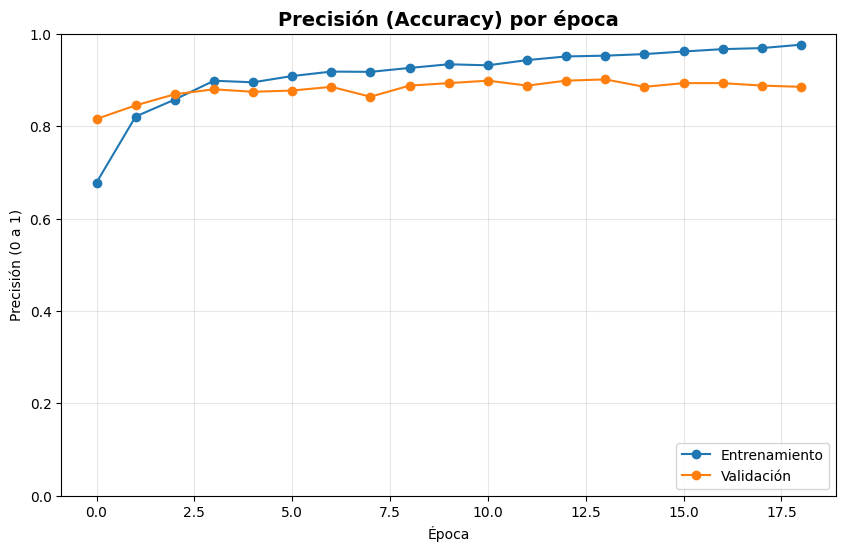

In [17]:
# GRAFICA DE PRECISION (ACCURACY)
# - Si ambas suben juntas -> el modelo esta aprendiendo bien.
# - Si entrenamiento sube mucho y validacion se queda abajo -> sobreajuste.

plt.figure(figsize=(10, 6))
plt.plot(historial.history['accuracy'],     marker='o', label='Entrenamiento')
plt.plot(historial.history['val_accuracy'], marker='o', label='Validación')
plt.title('Precisión (Accuracy) por época', fontsize=14, fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Precisión (0 a 1)')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

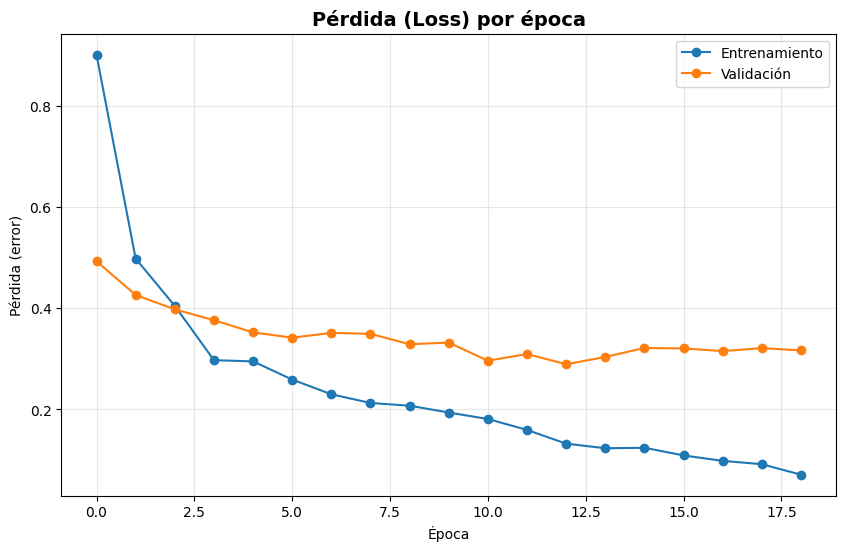

In [18]:
# GRAFICA DE PERDIDA (LOSS)
# El "loss" (error) mide que tan equivocado esta el modelo. DEBE BAJAR con las epocas.
# - Si el loss de validacion SUBE mientras el de entrenamiento baja -> sobreajuste.

plt.figure(figsize=(10, 6))
plt.plot(historial.history['loss'],     marker='o', label='Entrenamiento')
plt.plot(historial.history['val_loss'], marker='o', label='Validación')
plt.title('Pérdida (Loss) por época', fontsize=14, fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Pérdida (error)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
# AJUSTE FINO (FINE TUNING)
# Se descongela el modelo base y se entrena con una tasa muy baja (1e-5 = 0.00001).
# Esto ajusta finamente la red al dataset de residuos y suele subir la precision.

modelo_base.trainable = True   # DESCONGELAMOS el modelo base

# Las capas BatchNormalization se dejan congeladas para no desestabilizar el modelo
for capa in modelo_base.layers:
    if isinstance(capa, tf.keras.layers.BatchNormalization):
        capa.trainable = False

# Recompilar SIEMPRE despues de cambiar 'trainable', con tasa MUY baja
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

historial_ajuste = modelo.fit(
    datos_entrenamiento,
    validation_data=datos_validacion,
    epochs=10,                         # solo 10 epocas extra (es un ajuste fino)
    class_weight=peso_clases,
    callbacks=controles
)

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 277ms/step - accuracy: 0.9570 - loss: 0.1245 - val_accuracy: 0.8957 - val_loss: 0.2954 - learning_rate: 1.0000e-05
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 231ms/step - accuracy: 0.9633 - loss: 0.0997 - val_accuracy: 0.8930 - val_loss: 0.2972 - learning_rate: 1.0000e-05
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.9771 - loss: 0.0700
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 234ms/step - accuracy: 0.9723 - loss: 0.0784 - val_accuracy: 0.9037 - val_loss: 0.2922 - learning_rate: 1.0000e-05
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - accuracy: 0.9717 - loss: 0.0758 - val_accuracy: 0.9011 - val_loss: 0.2957 - learning_rate: 5.0000e-06
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - accuracy: 0.9740 - loss: 0.0726 - val_accuracy: 0.9011 - val_loss: 0.2887 - learning_rate: 5.0000e-06
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 231ms/step - accuracy:

# FASE 5 - EVALUACIÓN

In [20]:
# VERIFICACION DE PREDICCIONES
print("=" * 60)
print("VERIFICACIÓN DE PREDICCIONES")
print("=" * 60)
for imagenes, etiquetas in datos_prueba.take(1):
    predicciones = modelo.predict(imagenes)
    confianza = np.max(predicciones, axis=1)
    clases_predichas = np.argmax(predicciones, axis=1)
    for i in range(min(10, len(etiquetas))):
        clase_real = nombre_clases[int(etiquetas[i])]
        clase_predicha = nombre_clases[clases_predichas[i]]
        print(f"Clase Real     : {clase_real}")
        print(f"Clase Predicha : {clase_predicha}")
        print(f"Confianza      : {confianza[i]*100:.2f}%")
        print("-" * 50)

VERIFICACIÓN DE PREDICCIONES
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Clase Real     : metal
Clase Predicha : metal
Confianza      : 100.00%
--------------------------------------------------
Clase Real     : glass
Clase Predicha : metal
Confianza      : 93.79%
--------------------------------------------------
Clase Real     : trash
Clase Predicha : plastic
Confianza      : 96.75%
--------------------------------------------------
Clase Real     : trash
Clase Predicha : trash
Confianza      : 92.91%
--------------------------------------------------
Clase Real     : glass
Clase Predicha : glass
Confianza      : 99.97%
--------------------------------------------------
Clase Real     : glass
Clase Predicha : glass
Confianza      : 99.14%
--------------------------------------------------
Clase Real     : paper
Clase Predicha : paper
Confianza      : 99.98%
--------------------------------------------------
Clase Real     : glass
Clase Predicha : glass
Confianza      : 76.91%
---------------

In [21]:
# HERRAMIENTAS DE EVALUACION (scikit-learn)
from sklearn.metrics import classification_report   # reporte: precision, recall, f1 por clase
from sklearn.metrics import confusion_matrix        # tabla de aciertos vs confusiones

In [22]:
# ============================================================
# EVALUACION FINAL CON DATOS DE PRUEBA
# ============================================================
# Mide el rendimiento REAL con imagenes que el modelo NUNCA vio al entrenar.

perdida_prueba, exactitud_prueba = modelo.evaluate(datos_prueba)

print(f"\nPrecisión final en prueba: {exactitud_prueba*100:.2f}%")
print(f"Pérdida final en prueba:   {perdida_prueba:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9036 - loss: 0.2986

Precisión final en prueba: 90.36%
Pérdida final en prueba:   0.2986


In [23]:
# ============================================================
# OBTENER PREDICCIONES PARA EL REPORTE Y LA MATRIZ
# ============================================================
etiquetas_reales = []      # clases verdaderas
etiquetas_predichas = []   # clases que adivina el modelo

for imagenes, etiquetas in datos_prueba:
    prediccion = modelo.predict(imagenes, verbose=0)
    etiquetas_reales.extend(etiquetas.numpy())
    etiquetas_predichas.extend(np.argmax(prediccion, axis=1))  # elige la clase con mayor probabilidad

In [24]:
# ============================================================
# REPORTE DE CLASIFICACION
# ============================================================
#   - precision: de lo que predijo como X, cuanto era realmente X
#   - recall:    de todo lo que era X, cuanto detecto
#   - f1-score:  equilibrio entre precision y recall (1.0 = perfecto)
print(classification_report(
    etiquetas_reales,
    etiquetas_predichas,
    target_names=nombre_clases,
    zero_division=0
))

              precision    recall  f1-score   support

   cardboard       0.88      0.93      0.90        61
       glass       0.94      0.93      0.93        81
       metal       0.86      0.95      0.90        58
       paper       0.93      0.89      0.91        90
     plastic       0.93      0.87      0.90        71
       trash       0.82      0.78      0.80        23

    accuracy                           0.90       384
   macro avg       0.89      0.89      0.89       384
weighted avg       0.90      0.90      0.90       384



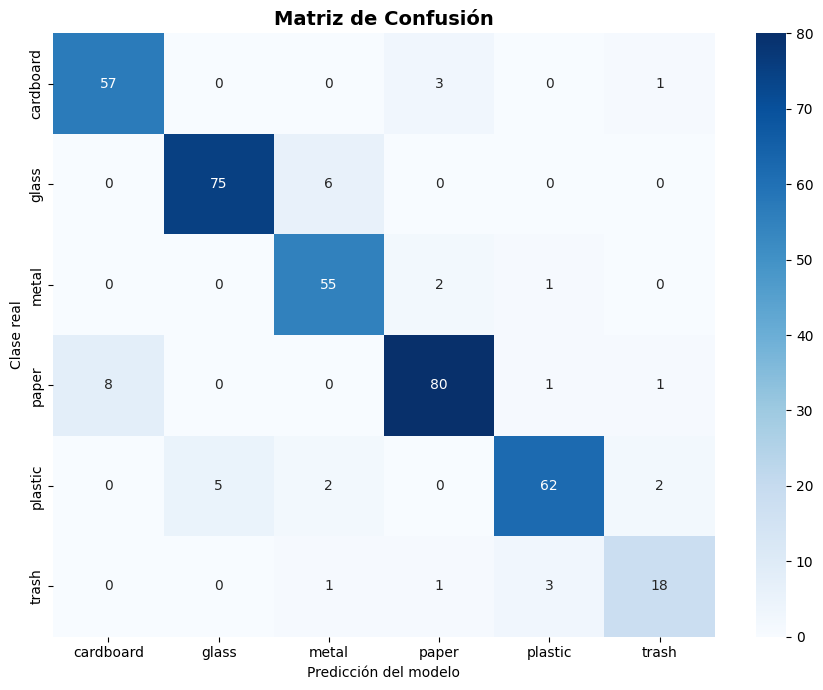

In [25]:
# ============================================================
# MATRIZ DE CONFUSION
# ============================================================
# Filas = clase REAL, columnas = clase PREDICHA.
# La DIAGONAL son los ACIERTOS; fuera de la diagonal son CONFUSIONES.

matriz = confusion_matrix(etiquetas_reales, etiquetas_predichas)

plt.figure(figsize=(9, 7))
sns.heatmap(
    matriz,
    annot=True,                 # escribe el numero dentro de cada celda
    fmt='d',                    # formato de numero entero
    cmap='Blues',               # escala de color azul
    xticklabels=nombre_clases,
    yticklabels=nombre_clases
)
plt.title('Matriz de Confusión', fontsize=14, fontweight='bold')
plt.xlabel('Predicción del modelo')
plt.ylabel('Clase real')
plt.tight_layout()
plt.show()

# FASE 6 - DESPLIEGUE

In [26]:
# GUARDAR EL MODELO ENTRENADO
# Guarda toda la red (arquitectura + pesos aprendidos) en un solo archivo.
# Asi se puede reutilizar despues SIN volver a entrenar (ej. en una API con FastAPI).
modelo.save("modelo_residuos.keras")

In [27]:
# DESCARGAR EL MODELO A TU COMPUTADORA
from google.colab import files
files.download("modelo_residuos.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Clasificación de una imagen real

Se sube una fotografía desde la computadora y el modelo la clasifica. Si la confianza es menor al 75%, el sistema responde "desconocido" para evitar clasificaciones poco seguras.

In [28]:
from tensorflow.keras.preprocessing import image

def predecir_seguro(ruta_imagen):
    # Cargar y redimensionar la imagen a 224x224 (tamano que espera el modelo)
    img = image.load_img(ruta_imagen, target_size=(224, 224))
    img_array = image.img_to_array(img)          # convertir a arreglo de pixeles [0, 255]
    img_array = np.expand_dims(img_array, axis=0)  # agregar dimension de lote: (1, 224, 224, 3)

    predicciones = modelo.predict(img_array, verbose=0)
    indice = np.argmax(predicciones)
    confianza = float(np.max(predicciones))

    if confianza < 0.75:
        return {"clase": "desconocido", "confianza": confianza}

    return {"clase": nombre_clases[indice], "confianza": confianza}

Saving WhatsApp Image 2026-10-14 at 21.00.16.jpeg to WhatsApp Image 2026-10-14 at 21.00.16.jpeg


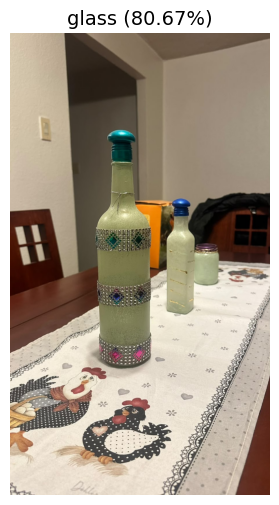

Clase detectada: glass
Confianza: 80.67%


In [31]:
# SUBIR UNA FOTO DESDE LA COMPUTADORA Y CLASIFICARLA
from google.colab import files

subida = files.upload()   # abre el selector de archivos

for nombre in subida:
    resultado = predecir_seguro(nombre)

    plt.figure(figsize=(6, 6))
    plt.imshow(image.load_img(nombre))
    plt.axis("off")
    plt.title(f"{resultado['clase']} ({resultado['confianza']*100:.2f}%)", fontsize=14)
    plt.show()

    print(f"Clase detectada: {resultado['clase']}")
    print(f"Confianza: {resultado['confianza']*100:.2f}%")

In [32]:
import json, nbformat
from nbconvert import HTMLExporter
from google.colab import _message, files

nb = _message.blocking_request('get_ipynb')['ipynb']
nb = nbformat.reads(json.dumps(nb), as_version=4)
html, _ = HTMLExporter().from_notebook_node(nb)

with open('notebook.html', 'w', encoding='utf-8') as f:
    f.write(html)
files.download('notebook.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>